Measure the gap between the average head and the head in the wells for different pumping rates and different settings.

In [609]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp

from Components.System import SimpleSquareExample
from Components.Model import IrrigationSchedulingModel, IrrigationSchedulingCost
from Components.Controllers import TimeVaryingCost_LQRc_RHG, LQRc_welfare

In [610]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.set_printoptions(linewidth=np.inf)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [611]:
parameter_file = "Components/Setup/stable_model_parameters.json"
crop_repartition = np.array([[0.5, 0.8, 0.3], [0., 0.2, 0.3], [0.4, 0., 0.3], [0., 0., 0.4]])

In [612]:
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = IrrigationSchedulingModel(parameter_file, boundary_condition="Constant Head")
cost_model = IrrigationSchedulingCost(parameter_file, model, crop_repartition)

In [613]:
Q, R, R_minus, M, L = cost_model.get_cost_matrices(0, controller.K)
([cost_model.Ri_v[v][0].max() for v in range(3)], [cost_model.Ri_v[v][0].min() for v in range(3)], [cost_model.Ri_v[v][0].mean() for v in range(3)]), ([cost_model.Li_v[v][0].max() for v in range(3)], [cost_model.Li_v[v][0].min() for v in range(3)], [cost_model.Li_v[v][0].mean() for v in range(3)])

(([np.float64(1.959183673469388e-06),
   np.float64(1.5943877551020406e-05),
   np.float64(6.112557870370371e-05)],
  [np.float64(0.0), np.float64(0.0), np.float64(0.0)],
  [np.float64(2.3182397959183675e-07),
   np.float64(1.1957908163265306e-06),
   np.float64(5.506856605489418e-06)]),
 ([np.float64(0.027428571428571434),
   np.float64(0.03571428571428571),
   np.float64(0.1760416666666667)],
  [np.float64(0.0), np.float64(0.0), np.float64(0.009523809523809525)],
  [np.float64(0.010357142857142858),
   np.float64(0.01607142857142857),
   np.float64(0.0762326388888889)]))

In [614]:
R_tmp = sp.block_diag([cost_model.Ri_v[v][0] for v in range(3)]).copy()
L_tmp = np.hstack([cost_model.Li_v[v][0] for v in range(3)]).copy()

In [615]:
Q, R, R_minus, M, L = cost_model.get_cost_matrices(0, controller.K)
([cost_model.Ri_v[v][0].max() for v in range(3)], [cost_model.Ri_v[v][0].min() for v in range(3)], [cost_model.Ri_v[v][0].mean() for v in range(3)]), ([cost_model.Li_v[v][0].max() for v in range(3)], [cost_model.Li_v[v][0].min() for v in range(3)], [cost_model.Li_v[v][0].mean() for v in range(3)])

(([np.float64(1.959183673469388e-06),
   np.float64(1.5943877551020406e-05),
   np.float64(6.112557870370371e-05)],
  [np.float64(0.0), np.float64(0.0), np.float64(0.0)],
  [np.float64(2.3182397959183675e-07),
   np.float64(1.1957908163265306e-06),
   np.float64(5.506856605489418e-06)]),
 ([np.float64(0.027428571428571434),
   np.float64(0.03571428571428571),
   np.float64(0.1760416666666667)],
  [np.float64(0.0), np.float64(0.0), np.float64(0.009523809523809525)],
  [np.float64(0.010357142857142858),
   np.float64(0.01607142857142857),
   np.float64(0.0762326388888889)]))

In [616]:
np.linalg.eigvals(np.linalg.inv(np.eye(model.A.shape[0])-model.A))

array([29.38937505, 11.94936329, 11.94936329,  7.49922951,  6.17392784,  6.17392784,  4.72518316,  4.72518316,  3.44926326,  3.20308305,  3.80896305,  3.80896305,  2.65082731,  2.56092317,  3.20308305,  2.34246192,  2.65082731,  2.56092317,  2.03644674,  2.01294248,  1.97946793,  2.34246192,  1.83000783,  1.65083662,  1.97946793,  2.01294248,  1.63535706,  1.83000783,  0.60754297,  1.60068964,  1.38801071,  1.65083662,  1.51252105,  1.63535706,  1.60068964,  1.40438696,  0.64655745,  0.62644335,  1.37874377,  1.51252105,  1.35238794,  0.62644335,  1.40438696,  1.37874377,  0.7193815 ,  1.35238794,  0.65874914,  1.31282693,  1.12402419,  1.26527914,  0.68102819,  0.70548661,  1.31282693,  1.26527914,  0.65874914,  0.73110062,  0.68102819,  0.70548661,  0.73110062,  0.84107924,  1.12402419,  0.79802173,  0.76760152,  0.77548487,  1.08898656,  0.88218098,  0.98149665,  0.77548487,  0.76760152,  1.04216119,  0.79802173,  0.88218098,  0.98149665,  1.08898656,  0.85119876,  1.19047619,  0.84

# Study trajectory over increasingly large horizon

In [617]:
K_range = range(10,100,20)

In [618]:
list(K_range)

[10, 30, 50, 70, 90]

In [ ]:
n_well = int(sum(np.hstack(model.n_well_per_command)))
well_to_agent = np.zeros((model.n_agent, n_well))
indices = np.array(list(zip(model.well_to_agent.tolist(), range(n_well)))).T
well_to_agent[indices[0, :], indices[1, :]] = 1

In [636]:
traj = []
inputs_l = []
for K in K_range:
    # Initialize Controller
    controller = TimeVaryingCost_LQRc_RHG(
        parameter_file,
        model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
        model.H_x, model.h_x, model.H_u_v, model.h_u_v,
        model.H_xu_x, model.H_xu_u, model.h_xu,
        solver='fbrs',
        overwrite_time_horizon=K
    )
    Q, R, R_minus, M, L = cost_model.get_cost_matrices(0, controller.K)
    controller.update_cost_matrices(Q, R, R_minus, M, L)
    inputs, x_pred = controller.step(model.state-5)
    inputs_l.append(model.translate_input(inputs.T))
    traj.append(model.select_wells(x_pred))

In [665]:
well_order = (sp.hstack([w2c.T @ u2c for u2c, w2c in zip([sp.eye(n_c) for n_c in model.n_command_v], model.well_to_command_v)]) / np.hstack(model.n_well_per_command)).toarray()

In [620]:
np.trace(inputs @ sp.block_diag([cost_model.Ri_v[v][0] for v in range(3)]) @ inputs.T) + (np.hstack([cost_model.Li_v[v][0] for v in range(3)]) @ inputs.T).sum()

np.float64(-43144.26697116072)

In [621]:
-21696.90578183619

-21696.90578183619

In [640]:
plt.rcParams.update({'font.size': 15})

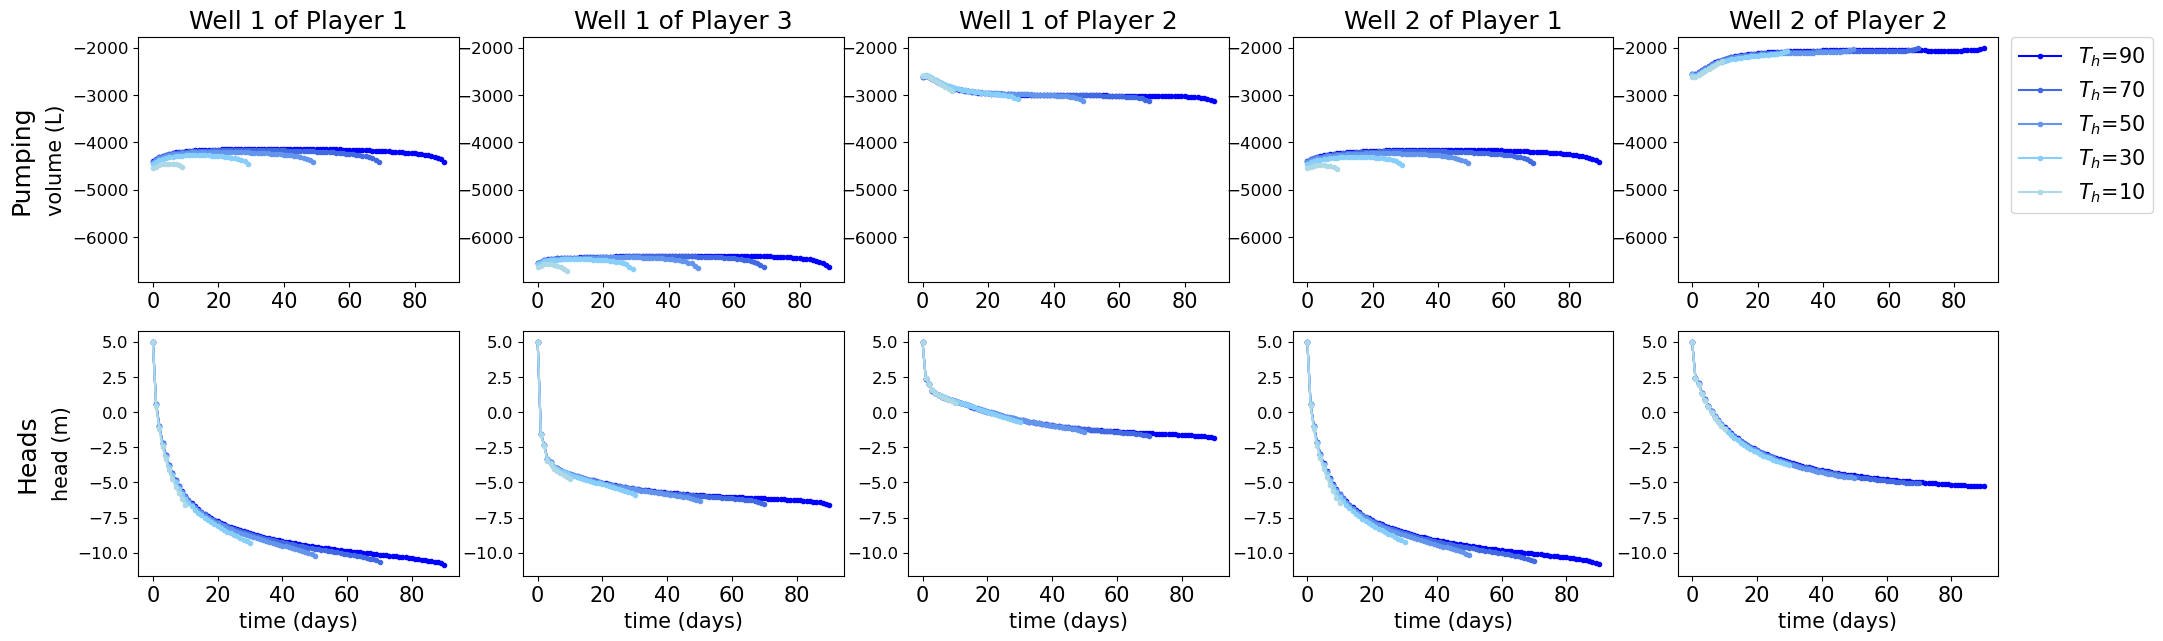

In [677]:
colors=['lightblue', 'lightskyblue', 'cornflowerblue', 'royalblue', 'blue']
to_player = [0, 2, 1, 0, 1]
n_well_of_player = [1, 1, 1, 2, 2]

fig_h = plt.figure(figsize=(24,7))
ax_q = None
for ii in range(5):
    ax_q = fig_h.add_subplot(2, 5, ii+1, sharey=ax_q)
    ax_q.tick_params(axis='y', which='major', labelsize=12)
    ttl = f"Well {n_well_of_player[ii]} of Player {to_player[ii]+1}"
    ax_q.set_title(ttl)
    # ax_q.set_xlabel("time (days)")
    if ii == 0:
        ax_q.set_ylabel("volume (L)")
        ax_q.annotate('Pumping', xy=(0, 0.5), xytext=(-ax_q.yaxis.labelpad - 5, 0),
                xycoords=ax_q.yaxis.label, textcoords='offset points',
                size='large', ha='right', va='center', rotation=90)
    for k, K in enumerate(reversed(K_range)):
        t = np.linspace(0,K, K+1)
        ax_q.plot(inputs_l[len(K_range)-1-k][ii,:], color= colors[len(K_range)-1-k], marker='.', label=f'$T_h$={K}')
ax_q.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(2, 5, 5+ii+1, sharey=ax_h)
    ax_h.tick_params(axis='y', which='major', labelsize=12)
    ax_h.set_xlabel("time (days)")
    if ii == 0:
        ax_h.set_ylabel("head (m)")
        ax_h.annotate('Heads', xy=(0, 0.5), xytext=(-ax_h.yaxis.labelpad - 5, 0),
                xycoords=ax_h.yaxis.label, textcoords='offset points',
                size='large', ha='right', va='center', rotation=90)
    for k, K in enumerate(reversed(K_range)):
        t = np.linspace(0,K, K+1)
        ax_h.plot((traj[len(K_range)-1-k])[ii,:], color= colors[len(K_range)-1-k], marker='.', label=f'$T_h$={K}')

Effect bigger when pumping costs dominate
& Demand almost linear ?

# Compare RH and Rolling Horizon

In [599]:
parameter_file = "/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250802-155425/model_parameters.json"
crop_repartition = np.array([[0.5, 0.8, 0.3], [0., 0.2, 0.3], [0.4, 0., 0.3], [0., 0., 0.4]])
# Initialize System and Model
system = SimpleSquareExample(parameter_file, boundary_condition="Constant Head")
model = IrrigationSchedulingModel(parameter_file, boundary_condition="Constant Head")
cost_model = IrrigationSchedulingCost(parameter_file, model, crop_repartition)

In [600]:
water_req = cost_model._get_water_requirement(0, 365)
rain = cost_model._get_available_water(0, 365)

n_well = int(sum(np.hstack(model.n_well_per_command)))
well_to_agent = np.zeros((model.n_agent, n_well))
indices = np.array(list(zip(model.well_to_agent.tolist(), range(n_well)))).T
well_to_agent[indices[0, :], indices[1, :]] = 1

In [601]:
data_RH = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250802-155425/result_data.npz')
data_rolling = np.load('/Users/leonardchanfreau/Documents/ETHZ/Master Thesis/code/GroundWater_RGH/run_data/run_20250802-155110/result_data.npz')

In [602]:
player_pumping_RH = well_to_agent @ data_RH['q_rates']
player_pumping_rolling = well_to_agent @ data_rolling['q_rates']

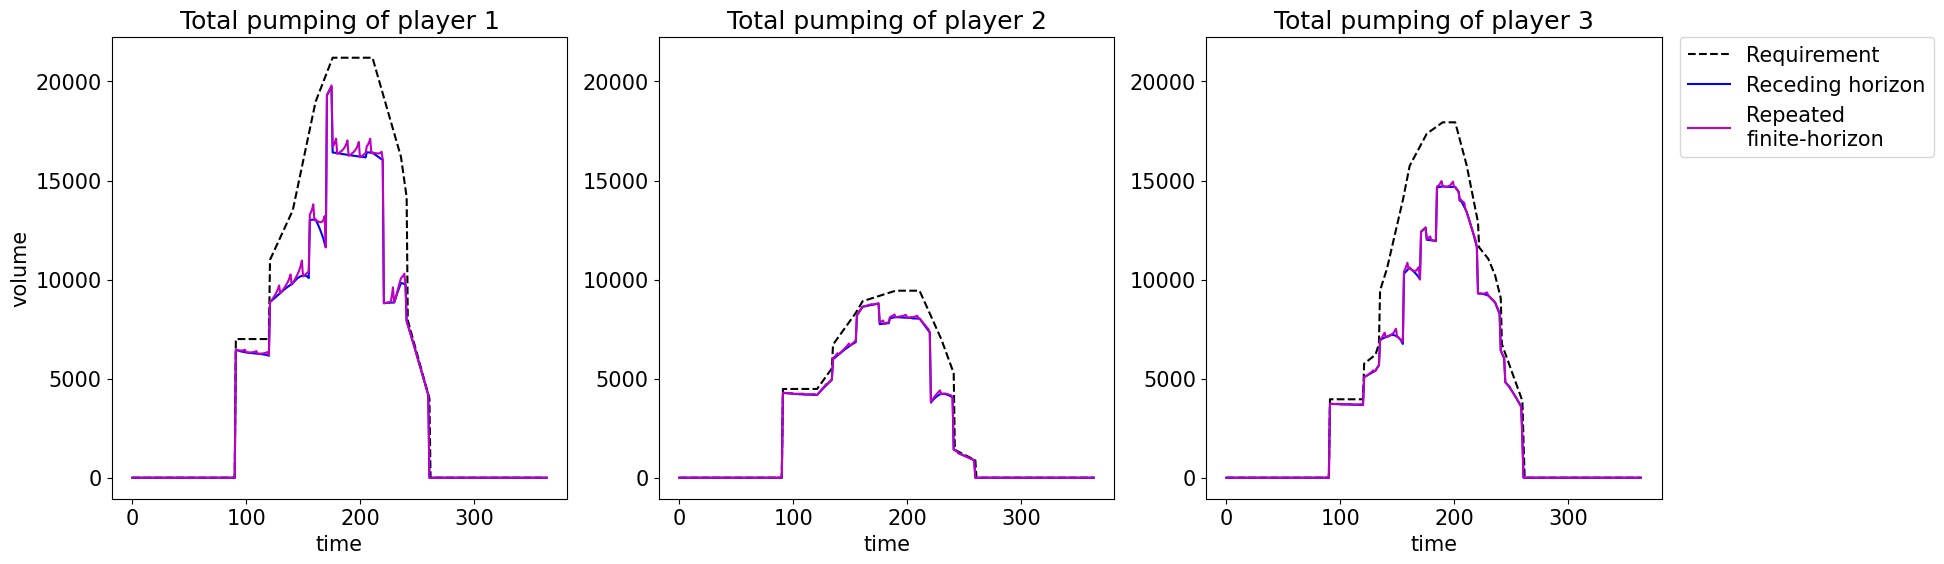

In [683]:
fig = plt.figure(figsize=(15+5,6))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Total pumping of player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("volume")
    ax.plot((water_req+rain)[ii, :, :].sum(axis=0), color='black', linestyle='--', label='Requirement')
    ax.plot(-player_pumping_RH[ii, :], "b-", label='Receding horizon')
    ax.plot(-player_pumping_rolling[ii, :], "m-", label='Repeated\nfinite-horizon')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_51012/3931781092.py:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


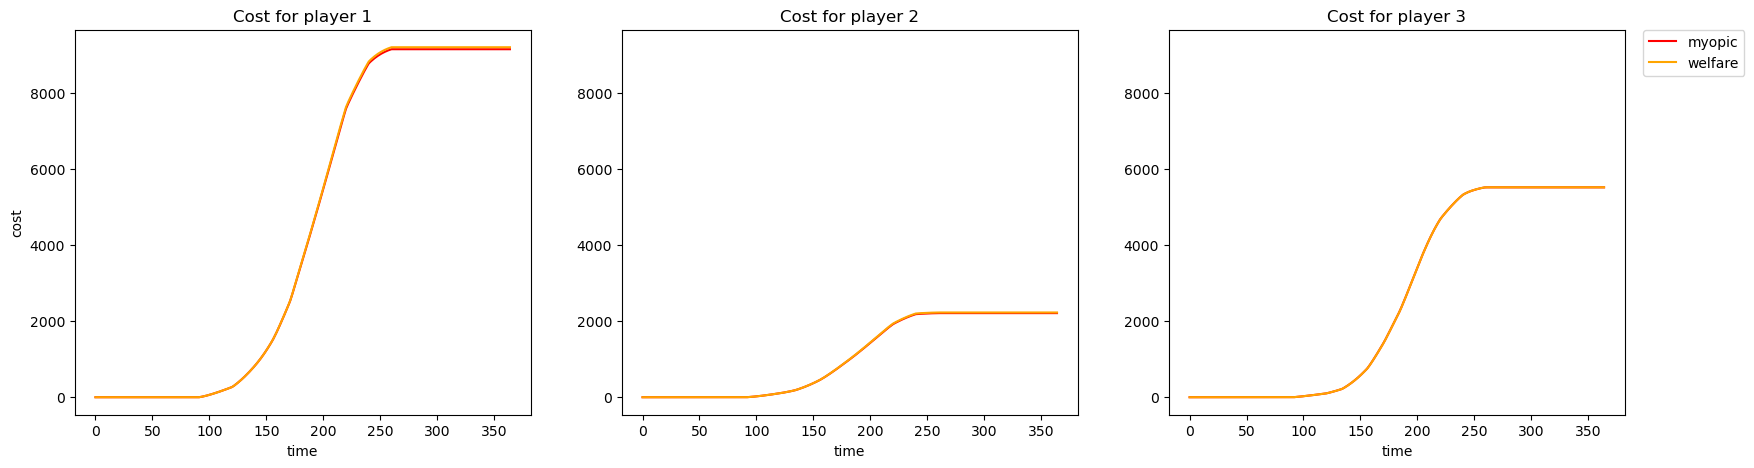

In [604]:
# Plot cost per player
fig = plt.figure(figsize=(15+5,5))
ax = None
for ii in range(3):
    ax = fig.add_subplot(1, 3, ii+1, sharey=ax)
    ttl = f"Cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-np.cumsum(data_RH['model_profit'][ii, :]), 'red', label='myopic')
    ax.plot(-np.cumsum(data_rolling['model_profit'][ii, :]), color="orange", label='welfare')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

In [605]:
def compute_cost(x: np.ndarray, u: np.ndarray, time: int = None) -> np.ndarray:
    """parameter u of shape [n_well, n_crops] contains negative values"""
    u = u.reshape((np.hstack(cost_model.n_well_per_command).sum(dtype=int), cost_model.n_crops))
    ET = cost_model._get_water_requirement(time, 1)[:,:,0]
    Ry = cost_model._get_under_irrigation_weight(time, 1)
    pumping_cost = np.zeros((cost_model.n_agent, 1))
    under_irrigation_cost = np.zeros((cost_model.n_agent, 1))
    for v in range(cost_model.n_agent):
        input_indices = np.nonzero(cost_model.well_to_cell[:,cost_model.well_to_agent==v].T)[1]
        well_indices = np.arange(np.hstack(cost_model.n_well_per_command).sum(), dtype=int)[cost_model.well_to_agent==v]
        pumping_cost[v] = (-cost_model.extraction_cost[v] * (cost_model.top_head[input_indices] -\
            x[well_indices]).reshape(-1,1) * u[cost_model.well_to_agent==v,:].sum(axis=1).reshape(-1,1)).sum()
        under_irrigation = ET[v, :] + u[cost_model.well_to_agent==v,:].sum(axis=0)    # TODO: check dimensions
        under_irrigation_cost[v] = \
            under_irrigation.T @ sp.diags(Ry[v,:].flatten()) @ under_irrigation.T
    return pumping_cost, under_irrigation_cost

In [606]:
costs_RH = np.hstack([- np.vstack(compute_cost(data_RH['corrected_h_wells'][:,[t+1]],
                                     model.reorganize_input_per_well(data_RH['inputs'][:,[t]]),
                                     t)) for t in range(364)])
costs_rolling = np.hstack([- np.vstack(compute_cost(data_rolling['corrected_h_wells'][:,[t+1]],
                                     model.reorganize_input_per_well(data_rolling['inputs'][:,[t]]),
                                     t)) for t in range(364)])

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_51012/1763459061.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


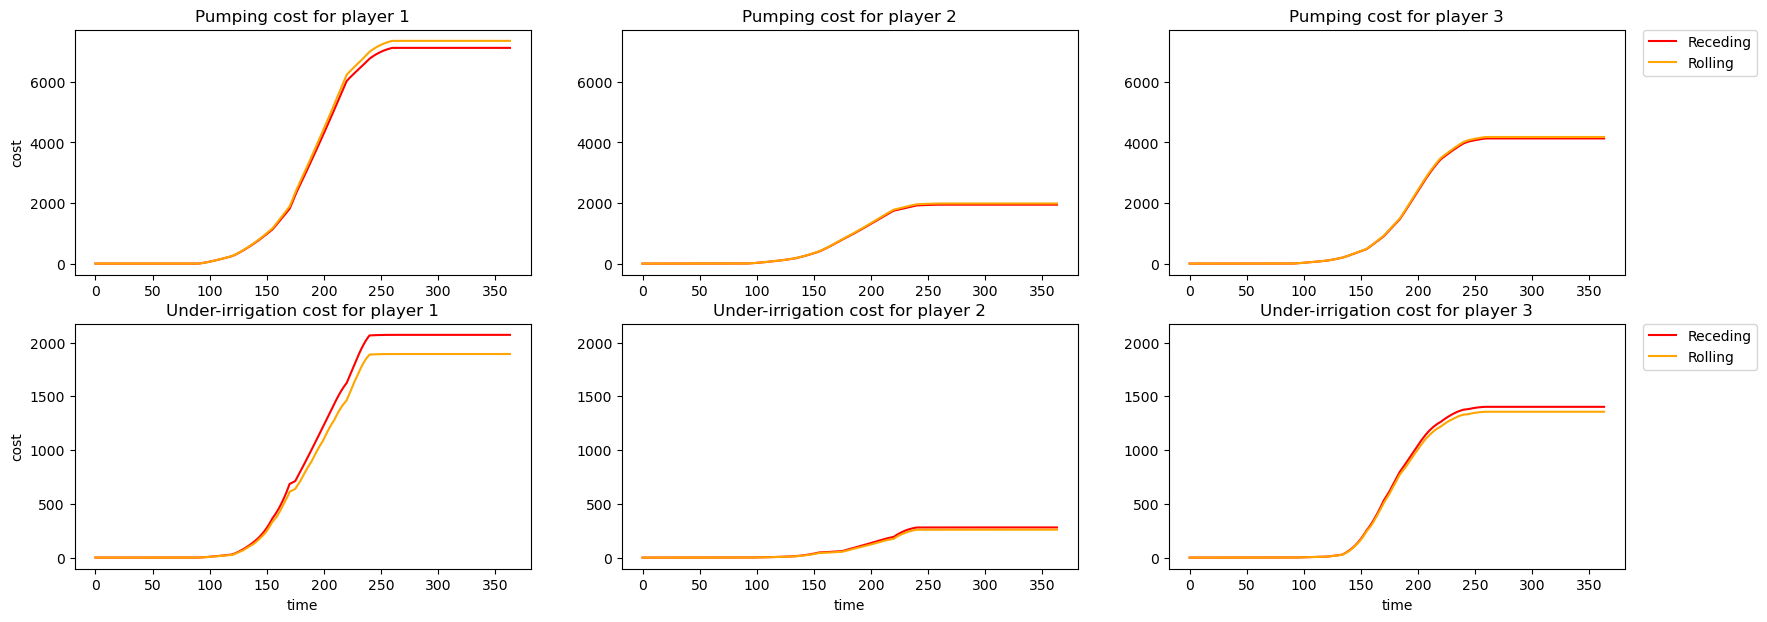

In [607]:
# Plot cost per player
fig = plt.figure(figsize=(15+5,7))
ax = None
for ii in range(3):
    ax = fig.add_subplot(2, 3, ii+1, sharey=ax)
    ttl = f"Pumping cost for player {ii+1}"
    ax.set_title(ttl)
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-np.cumsum(costs_RH[ii, :]), 'red', label='Receding')
    ax.plot(-np.cumsum(costs_rolling[ii, :]), color="orange", label='Rolling')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

ax = None
for ii in range(3):
    ax = fig.add_subplot(2, 3, 3+ii+1, sharey=ax)
    ttl = f"Under-irrigation cost for player {ii+1}"
    ax.set_title(ttl)
    ax.set_xlabel("time")
    if ii == 0:
        ax.set_ylabel("cost")
    ax.plot(-np.cumsum(costs_RH[ii+3, :]), 'red', label='Receding')
    ax.plot(-np.cumsum(costs_rolling[ii+3, :]), color="orange", label='Rolling')
ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)
fig.show()

In [684]:
costs_augmentation_rolling = np.where(abs(costs_RH)<=1e-10, 0, ((costs_rolling-costs_RH)/costs_RH))
total_cost_augmentation_rolling = np.where(abs(((np.kron([[1,1]], np.eye(3)) @ costs_RH)))<=1e-10, 0, ((np.kron([[1,1]], np.eye(3)) @ (costs_rolling))/((np.kron([[1,1]], np.eye(3)) @ costs_RH))) - 1)

cum_costs_augmentation_rolling = np.where(abs(np.cumsum(costs_RH, axis=1))<=1e-10, 0, ((np.cumsum(costs_rolling, axis=1)-np.cumsum(costs_RH, axis=1))/np.cumsum(costs_RH, axis=1)))
cum_total_cost_augmentation_rolling = np.where(abs(((np.kron([[1,1]], np.eye(3)) @ np.cumsum(costs_RH, axis=1))))<=1e-10, 0, ((np.kron([[1,1]], np.eye(3)) @ (np.cumsum(costs_rolling, axis=1)))/((np.kron([[1,1]], np.eye(3)) @ np.cumsum(costs_RH, axis=1)))) - 1)

/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_51012/3605369141.py:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()
/var/folders/6g/x154xgtn6qd532hcd7zkfr940000gn/T/ipykernel_51012/3605369141.py:38: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


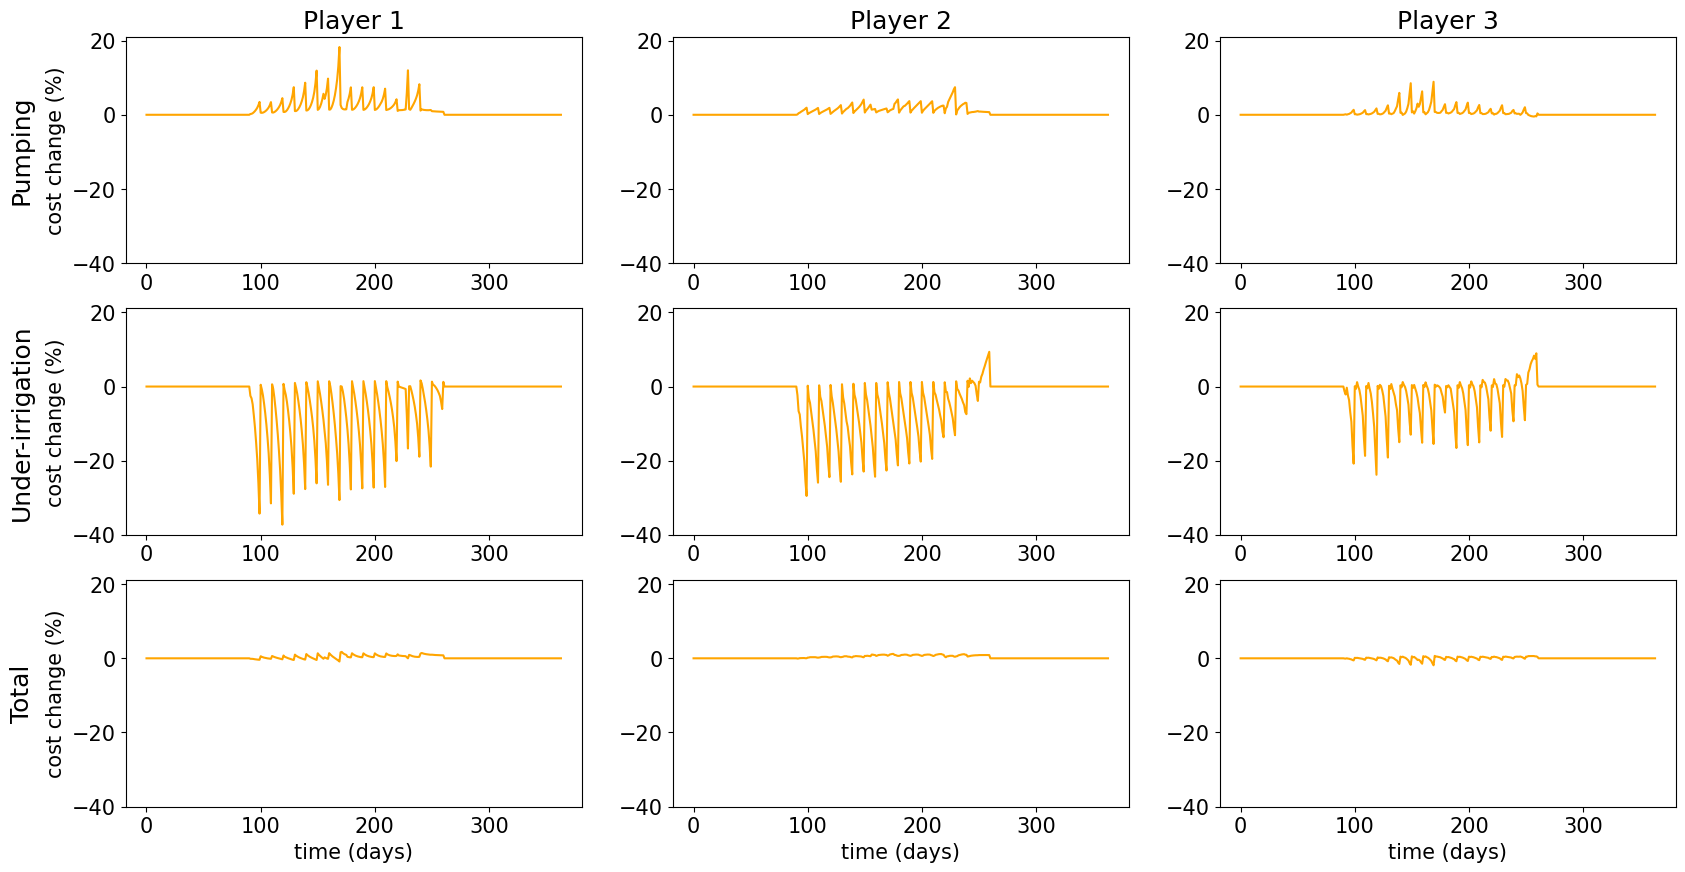

In [685]:
plt.rcParams.update({'font.size': 15})
# Plot cost per player
fig = plt.figure(figsize=(20,10))
ax = None
for ii in range(3):
    ax = fig.add_subplot(3, 3, ii+1, sharey=ax)
    ttl = f"Player {ii+1}"
    ax.set_title(ttl)
    if ii == 0:
        ax.set_ylabel("cost change (%)")
        ax.annotate('Pumping', xy=(0, 0.5), xytext=(-ax.yaxis.labelpad - 5, 0),
                xycoords=ax.yaxis.label, textcoords='offset points',
                size='large', ha='right', va='center', rotation=90)
    ax.plot(100*(costs_augmentation_rolling[ii, :]), color="orange", label='rolling')
#leg = ax.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

#ax=None
for ii in range(3):
    ax = fig.add_subplot(3, 3, 3+ii+1, sharey=ax)
    if ii == 0:
        ax.set_ylabel("cost change (%)")
        ax.annotate('Under-irrigation', xy=(0, 0.5), xytext=(-ax.yaxis.labelpad - 5, 0),
                xycoords=ax.yaxis.label, textcoords='offset points',
                size='large', ha='right', va='center', rotation=90)
    ax.plot(100*(costs_augmentation_rolling[ii+3, :]), color="orange", label='rolling')
fig.show()

#ax=None
for ii in range(3):
    ax = fig.add_subplot(3, 3, 6+ii+1, sharey=ax)
    ax.set_xlabel("time (days)")
    if ii == 0:
        ax.set_ylabel("cost change (%)")
        ax.annotate('Total', xy=(0, 0.5), xytext=(-ax.yaxis.labelpad - 5, 0),
                xycoords=ax.yaxis.label, textcoords='offset points',
                size='large', ha='right', va='center', rotation=90)
    ax.plot(100*(total_cost_augmentation_rolling[ii, :]), color="orange", label='welfare')
fig.show()

In [686]:
cum_costs_augmentation_rolling[:,-1]

array([ 0.03254542,  0.01978475,  0.01147883, -0.08599467, -0.0750261 , -0.03263258])